## 선형 회귀 예시2

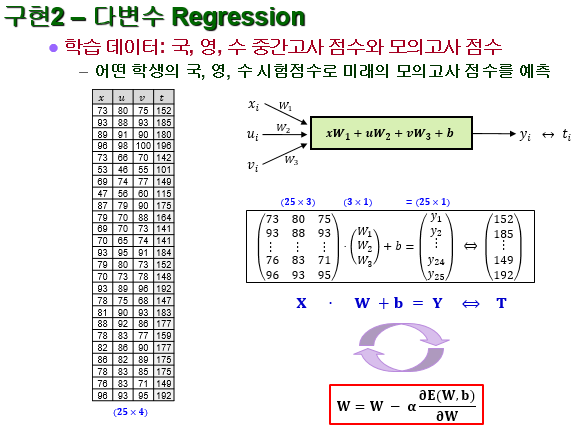

In [1]:
import numpy as np

raw_data = np.array(
            [[73, 80, 75, 152],
             [93, 88, 93, 185],
             [89, 91, 90, 180],
             [96, 98, 100, 196],
             [73, 66, 70, 142],
             [53, 46, 55, 101],
             [69, 74, 77, 149],
             [47, 56, 60, 115],
             [87, 79, 90, 175],
             [79, 70, 88, 164],
             [69, 70, 73, 141],
             [70, 65, 74, 141],
             [93, 95, 91, 184],
             [79, 80, 73, 152],
             [70, 73, 78, 148],
             [93, 89, 96, 192],
             [78, 75, 68, 147],
             [81, 90, 93, 183],
             [88, 92, 86, 177],
             [78, 83, 77, 159],
             [82, 86, 90, 177],
             [86, 82, 89, 175],
             [78, 83, 85, 175],
             [76, 83, 71, 149],
             [96, 93, 95, 192]], dtype='f')

# raw_data = np.loadtxt('/content/drive/My Drive/ColabNB/Data/data-01.csv', delimiter=',')

x_data = raw_data[ :, 0:-1]
t_data = raw_data[ :, [-1]]

# 데이터 차원 및 shape 확인
print("x_data.ndim = ", x_data.ndim, ", x_data.shape = ", x_data.shape)
print("t_data.ndim = ", t_data.ndim, ", t_data.shape = ", t_data.shape)
# print(x_data)
# print(t_data)

x_data.ndim =  2 , x_data.shape =  (25, 3)
t_data.ndim =  2 , t_data.shape =  (25, 1)


In [3]:
W = np.random.rand(3,1)  # 3X1 행렬
b = np.random.rand(1)
print("W = \n", W, ", W.shape = ", W.shape, "\nb = ", b, ", b.shape = ", b.shape)

W = 
 [[0.34075796]
 [0.24355863]
 [0.38018546]] , W.shape =  (3, 1) 
b =  [0.49955618] , b.shape =  (1,)


In [4]:
def lossFunc():     # E(W, b): 손실함수로서 W나 b값에 따른  x 데이터와 t 레이블의 MSE 리턴
    y = np.dot(x_data,W) + b
    return np.sum((t_data - y)**2) / len(x_data)   # 손실값 리턴

def numerical_derivative(fn, param):    # 주어진 함수 fn에 대한 W 또는 b에 대한 수치미분
    delta = 1e-4  # 0.0001          # 실제 미분함수를 구하지 않고 특정 W, b의 +/- 0.0001 범위에서 기울기 구함
    grad = np.zeros_like(param)     # 주어진 각 W 또는 b들에 대한 기울기 값 저장

    it = np.nditer(param, flags=['multi_index'], op_flags=['readwrite'])  # 다차원 배열 원소들의 순서참조 지원 함수
    while not it.finished:
        idx = it.multi_index
        temp = param[idx]            # 주어진 W, b값(기울기 대상지점값)을 저장해두고 기울기 계산 후 다시 원상태로 되돌림

        param[idx] = temp + delta
        loss1 = fn()           # W 또는 b의 약간의 증가치(+0.0001)에 대한 손실함수 값
        param[idx] = temp - delta
        loss2 = fn()           # W 또는 b의 약간의 감소치(-0.0001)에 대한 손실함수 값

        grad[idx] = (loss1-loss2) / (2*delta)    # 주어진 W, b의 미세한 구간에서의 손실함수값의 변화량 --> 기울기

        param[idx] = temp            # 기울기값 계산시 사용된 주어진 값의 사용이 끝난뒤 원래 값으로 되돌린다.
        it.iternext()
    return grad

def grad_descent(learning_rate, repeat, outStep):
    global W, b

    print("Initial error value = {:.3f}".format(lossFunc()))
    # print("Initial W = ", W.flatten().round(3))
    # print("Initial b = ", b.round(3))
    for step in range(repeat+1):        # 적당한 횟수만큼 경사하강 반복
        W -= learning_rate * numerical_derivative(lossFunc, W)
        b -= learning_rate * numerical_derivative(lossFunc, b)

        if (step % outStep == 0):       # 경사하강 반복 중간마다 손실값 출력
            print("Step = {:>6d}".format(step), "\tError Value = {:.4f}".format(lossFunc()),
                  "\tW =", W.flatten().round(3), "\tb = ", b.round(3))

# 학습을 마친 후, 임의의 데이터에 대해 미래 값 예측 함수
def predict(x):         # 입력변수 x : numpy type
    y = np.dot(x,W) + b
    return y

In [5]:
W = np.random.rand(3,1)  # 3X1 행렬
b = np.random.rand(1)

learning_rate = 1e-5  # 1e-2, 1e-3 은 손실함수 값이 발산함
repeat = 15000
outStep = 1000
grad_descent(learning_rate, repeat, outStep)

Initial error value = 910.690
Step =      0 	Error Value = 348.3887 	W = [0.581 0.797 0.417] 	b =  [0.793]
Step =   1000 	Error Value = 11.5578 	W = [0.585 0.729 0.701] 	b =  [0.793]
Step =   2000 	Error Value = 8.5893 	W = [0.532 0.641 0.838] 	b =  [0.792]
Step =   3000 	Error Value = 7.3058 	W = [0.491 0.589 0.929] 	b =  [0.79]
Step =   4000 	Error Value = 6.7397 	W = [0.46  0.558 0.99 ] 	b =  [0.789]
Step =   5000 	Error Value = 6.4836 	W = [0.437 0.54  1.03 ] 	b =  [0.787]
Step =   6000 	Error Value = 6.3639 	W = [0.418 0.53  1.057] 	b =  [0.786]
Step =   7000 	Error Value = 6.3060 	W = [0.404 0.525 1.076] 	b =  [0.784]
Step =   8000 	Error Value = 6.2767 	W = [0.393 0.523 1.089] 	b =  [0.782]
Step =   9000 	Error Value = 6.2613 	W = [0.385 0.522 1.098] 	b =  [0.78]
Step =  10000 	Error Value = 6.2528 	W = [0.379 0.522 1.104] 	b =  [0.778]
Step =  11000 	Error Value = 6.2480 	W = [0.374 0.523 1.108] 	b =  [0.776]
Step =  12000 	Error Value = 6.2450 	W = [0.37  0.523 1.111] 	b =  [0

In [6]:
test_data = np.array([[85, 90, 92],[92,90,85]]            )
print("Prediction of data: \n{} \n==> \n{}".format(test_data, predict(test_data).round(1)))

Prediction of data: 
[[85 90 92]
 [92 90 85]] 
==> 
[[181.6]
 [176.3]]
